# Reproducing the official pre-registered results

This notebook recomputes the official, pre-registered contrasts of the study from the published extract `data/lives.parquet` and compares them, number by number, with `data/reference.json` (the values computed in the original study). Nothing new is analysed here: the goal is to show that the published data reproduces the official numbers exactly.

**The study in one paragraph.** 9,600 simulated virtual-pet lives of 14 days each: 4 *arms* (what happens when the owner pets the pet right after it eats or plays) x 12 *cells* (4 owner types x 3 places) x 200 *units*. A unit is paired across arms: the same (unit, owner, place) appears once in every arm. See `data/SCHEMA.md` for the column dictionary.

## Setup
We read the data with DuckDB (SQL straight over the parquet file) and use `scipy` only for the exact Student-t quantile.

In [1]:
import json
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LIVES = (ROOT / "data" / "lives.parquet").as_posix()
ref = json.loads((ROOT / "data" / "reference.json").read_text())

MEASURES = ["awake_frac_d1_14", "awake_frac_d8_14", "time_well",
            "episode_rate", "eat_decisions", "play_decisions"]
CONTRASTS = ref["contrast_definitions"]  # D1, D2, D3 -> {a: arm, b: arm}
CONTRASTS

{'D1': {'a': 'petting_with_credit', 'b': 'no_petting'},
 'D2': {'a': 'petting_with_credit', 'b': 'petting_with_credit_random_time'},
 'D3': {'a': 'petting_with_credit', 'b': 'petting_body_only'}}

## The three contrasts
Each contrast compares two arms, A minus B:

- **D1** = petting_with_credit - no_petting
- **D2** = petting_with_credit - petting_with_credit_random_time
- **D3** = petting_with_credit - petting_body_only

The six measures are: share of decisions that were awake over days 1-14 (`awake_frac_d1_14`, the primary outcome) and over days 8-14, the share of decisions taken while the pet was neither deprived nor exhausted (`time_well`), the share of hunger episodes closed by eating (`episode_rate`), and the number of eat and play decisions.

## Step 1: one paired difference per unit (DuckDB)
For a contrast A - B and a measure, the official method works unit by unit. For each unit (1..200) and each of its 12 cells (owner, place) we take the measure in arm A minus the measure in arm B. Averaging these 12 differences gives one number per unit, so each contrast and measure ends up with 200 paired differences. The SQL below pivots the arms side by side per (unit, owner, place), subtracts, and averages over the 12 cells.

In [2]:
con = duckdb.connect()

def paired_differences(a, b, measure):
    """200 per-unit differences (A - B), averaged over the 12 (owner, place) cells."""
    sql = f"""
        WITH wide AS (
            SELECT unit, owner, place,
                   max({measure}) FILTER (WHERE arm = '{a}') AS a,
                   max({measure}) FILTER (WHERE arm = '{b}') AS b
            FROM read_parquet('{LIVES}')
            GROUP BY unit, owner, place
        )
        SELECT unit, avg(a - b) AS diff
        FROM wide
        GROUP BY unit
        ORDER BY unit
    """
    return con.execute(sql).df()["diff"].to_numpy()

d = paired_differences("petting_with_credit", "no_petting", "awake_frac_d1_14")
print(len(d), "paired differences; first three:", d[:3].round(5))

200 paired differences; first three: [-0.00862 -0.00862 -0.01104]


## Step 2: mean, 95% interval and effect size
From the 200 differences we compute:

- the **estimate**: their mean;
- the **95% confidence interval**: mean +/- t x sd / sqrt(200), with sd the sample standard deviation (ddof = 1) and t the exact Student-t quantile with 199 degrees of freedom (`scipy.stats.t.ppf(0.975, 199)`);
- the **effect size dz**: mean / sd of the same differences (reported for context; it is not in `reference.json`).

In [3]:
rows = []
for cid, defn in CONTRASTS.items():
    for m in MEASURES:
        d = paired_differences(defn["a"], defn["b"], m)
        n = len(d)
        mean, sd = d.mean(), d.std(ddof=1)
        half = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
        r = ref["contrasts"][m][cid]
        rows.append(dict(
            contrast=cid, measure=m, n=n, estimate=mean,
            ci_low=mean - half, ci_high=mean + half, dz=mean / sd,
            diff_est=abs(mean - r["mean"]),
            diff_low=abs(mean - half - r["ci_low"]),
            diff_high=abs(mean + half - r["ci_high"]),
        ))
res = pd.DataFrame(rows)
res["max_abs_diff"] = res[["diff_est", "diff_low", "diff_high"]].max(axis=1)
res[["contrast", "measure", "estimate", "ci_low", "ci_high", "dz", "max_abs_diff"]].round(4)

,contrast,measure,estimate,ci_low,ci_high,dz,max_abs_diff
0,D1,awake_frac_d1_14,-0.0109,-0.0113,-0.0105,-3.6952,0.0
1,D1,awake_frac_d8_14,-0.0062,-0.0069,-0.0056,-1.3813,0.0
2,D1,time_well,0.0183,0.0152,0.0215,0.8120,0.0
3,D1,episode_rate,0.0209,0.0147,0.0270,0.4753,0.0
4,D1,eat_decisions,14.1446,13.6399,14.6493,3.9078,0.0
5,D1,play_decisions,11.5279,10.9185,12.1373,2.6377,0.0
6,D2,awake_frac_d1_14,0.0096,0.0093,0.0100,3.5495,0.0
7,D2,awake_frac_d8_14,0.0124,0.0118,0.0130,2.9412,0.0
8,D2,time_well,0.0025,-0.0007,0.0056,0.1094,0.0
9,D2,episode_rate,0.0069,0.0009,0.0129,0.1593,0.0


## Step 3: headline numbers
The four headline results of the study, printed at four decimals.

In [4]:
headline = [("D1", "awake_frac_d1_14"), ("D1", "time_well"),
            ("D2", "awake_frac_d1_14"), ("D3", "awake_frac_d1_14")]
expected = {("D1", "awake_frac_d1_14"): "-0.0109 [-0.0113; -0.0105]",
            ("D1", "time_well"):        "+0.0183 [+0.0152; +0.0215]",
            ("D2", "awake_frac_d1_14"): "+0.0096 [+0.0093; +0.0100]",
            ("D3", "awake_frac_d1_14"): "+0.0070 [+0.0067; +0.0073]"}
fmt = lambda r: f"{r.estimate:+.4f} [{r.ci_low:+.4f}; {r.ci_high:+.4f}]"
table = []
for c, m in headline:
    r = res[(res.contrast == c) & (res.measure == m)].iloc[0]
    table.append(dict(contrast=c, measure=m, reproduced=fmt(r), expected=expected[(c, m)],
                      match=fmt(r) == expected[(c, m)]))
pd.DataFrame(table)

,contrast,measure,reproduced,expected,match
0,D1,awake_frac_d1_14,-0.0109 [-0.0113; -0.0105],-0.0109 [-0.0113; -0.0105],True
1,D1,time_well,+0.0183 [+0.0152; +0.0215],+0.0183 [+0.0152; +0.0215],True
2,D2,awake_frac_d1_14,+0.0096 [+0.0093; +0.0100],+0.0096 [+0.0093; +0.0100],True
3,D3,awake_frac_d1_14,+0.0070 [+0.0067; +0.0073],+0.0070 [+0.0067; +0.0073],True


## Step 4: one simple figure
The 200 per-unit differences behind the first headline number (D1, `awake_frac_d1_14`), with the mean and its 95% interval marked.

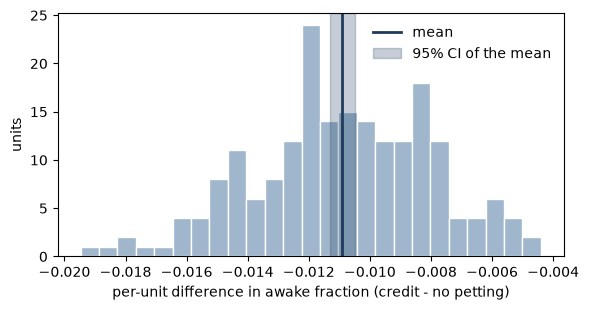

In [5]:
#| fig-alt: "Histogram of the 200 per-unit differences in awake fraction, petting with credit minus no petting. All 200 differences are below zero; their mean, -0.0109, is marked with its 95% interval [-0.0113; -0.0105], a narrow band entirely below zero."
import matplotlib.pyplot as plt

d = paired_differences(CONTRASTS["D1"]["a"], CONTRASTS["D1"]["b"], "awake_frac_d1_14")
r = res[(res.contrast == "D1") & (res.measure == "awake_frac_d1_14")].iloc[0]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(d, bins=25, color="#9fb6cd", edgecolor="white")
ax.axvline(r.estimate, color="#1f3b5c", lw=2, label="mean")
ax.axvspan(r.ci_low, r.ci_high, color="#1f3b5c", alpha=0.25, label="95% CI of the mean")
ax.set_xlabel("per-unit difference in awake fraction (credit - no petting)")
ax.set_ylabel("units")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Gate: the reproduction must match the official numbers
For every contrast x measure (18 rows), the estimate and both interval limits must be within 1e-9 of `reference.json`, and the four headline numbers must read exactly as above. If anything fails, this cell stops the notebook with an error; no tolerance or method is adjusted to make it pass.

In [6]:
TOL = 1e-9
assert len(res) == 18, len(res)
assert (res.n == 200).all()
bad = res[res.max_abs_diff > TOL]
assert bad.empty, "Mismatch vs reference.json:\n" + bad.to_string()
assert all(t["match"] for t in table), pd.DataFrame(table).to_string()
print(f"GATE PASSED: 18/18 contrast x measure rows within {TOL:g} of reference.json "
      f"(largest |diff| = {res.max_abs_diff.max():.2e}); 4/4 headline numbers match.")

GATE PASSED: 18/18 contrast x measure rows within 1e-09 of reference.json (largest |diff| = 7.11e-15); 4/4 headline numbers match.
